# Homework06

Some exercises with `pandas` `DataFrame`.

## Goals
- Get familiar with the `DataFrame` object and its functionalities
- Experiment with `DataFrame` filtering and searching

## Navigating Data

In this exercise we're going to explore the search and filter capabilities of the `DataFrame` to connect a couple of datasets and solve a mystery.

This is based on the [SQL Murder Mystery](https://mystery.knightlab.com/) exercise, but using different datasets created specifically for `pandas` and `DataFrame` objects.

Run the following $2$ cells to load the data and libraries we'll need.

In [28]:
!wget -qO- https://github.com/PSAM-5005-2026S-A/5005-utils/releases/latest/download/mystery.tar.gz | tar xz

In [29]:
import pandas as pd
from Homework06_utils import MysteryUtils

### The Data

We'll be working with data from $6$ different sources:

- `report.csv`: Database of reported crimes
- `testimony.csv`: Database of testimony taken by police
- `license.csv`: DMV data
- `person.csv`: Names, addresses, social security numbers
- `update.csv`: List of social media updates
- `cringe.csv`: Membership information for _Cringe Gym_

### The Functions

Loading these into `DataFrame` objects will help us organize, navigate and connect the data.

We can perform basic searches by indexing a `DataFrame` with boolean expressions. 

- This returna all rows with a value of `good` for the `rating` column:<br>
  `df[df["rating"] == "good"]`
- This returna all rows with a `grade` greater than $70$:<br>
  `df[df["grade"] > 70]`
- We can chain multiple conditions with boolean operator. To get all rows of `mammals` that weight more than $50$ $\text{kg}$:<br>
  `df[(df["class"] == "mammalia") & (df["weight"] > 50)]` (note the parenthesis)
- [More examples and documentation](https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing)


In addition to boolean indexing, the following functions can help us navigate and filter `DataFrame` objects efficiently:

- [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html): for sorting a `DataFrame` by column values
- [`str.contains()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.contains.html): for checking if a string contains a substring
- [`str.startswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.startswith.html): for checking if a string starts with a specific pattern
- [`isin()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html): for checking if a value matches one of a few choices
- [`isna()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.isna.html): for checking if a values is empty/null
- [`apply(axis=1)`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html): applies function to all rows of a `DataFrame`

### Loading Data

Let's get this out of the way and just load all `csv` datasets at once.

Take a look at their column names and a few rows to see what kind of data is in each.

In [30]:
gym_df = pd.read_csv("./data/csv/mystery/cringe.csv")
dmv_df = pd.read_csv("./data/csv/mystery/license.csv")
person_df = pd.read_csv("./data/csv/mystery/person.csv")
report_df = pd.read_csv("./data/csv/mystery/report.csv")
testimony_df = pd.read_csv("./data/csv/mystery/testimony.csv")
social_df = pd.read_csv("./data/csv/mystery/update.csv", keep_default_na=False)

In [31]:
# TODO: Look at datasets/DataFrames

print("GYM DATA")
display(gym_df.head())

print("DMV DATA")
display(dmv_df.head())

print("PERSON DATA")
display(person_df.head())

print("CRIME REPORTS")
display(report_df.head())

print("TESTIMONY")
display(testimony_df.head())

print("SOCIAL MEDIA")
display(social_df.head())

GYM DATA


,id,name,start,status
0,Z0GZP,Ronald Rolins,20240426,regular
1,5D78T,Williams Shoulder,20201227,regular
2,0RW3Y,Bernice Kuwahara,20230102,regular
3,76E2P,Micheal Dillis,20240809,regular
4,MIVQI,Wade Worland,20220914,regular


DMV DATA


,license_id,age,height,eye_color,hair_color,gender,plate_number,car_make,car_model
0,100280,72,57,brown,red,male,EFW9376,Acura,MDX
1,100460,63,72,brown,brown,female,XF02T6,Cadillac,SRX
2,101029,62,74,green,green,female,VKY5KR,Scion,xB
3,101198,43,54,amber,brown,female,EEW9997,Nissan,Rogue
4,101255,18,79,blue,grey,female,5162Z1,Lexus,GS


PERSON DATA


...

,date,type,description,borough
0,20241108,murder,Fatal stabbing during a street confrontation; ...,Manhattan
1,20250219,fraud,Sophisticated phishing attack targeting local ...,Manhattan
2,20230614,theft,Bicycle stolen from a high school rack; no wit...,Brooklyn
3,20240105,assault,Physical altercation in a parking lot; several...,Staten Island
4,20251225,arson,Structure fire at a vacant warehouse; suspicio...,Bronx


TESTIMONY


,ssn,date,transcript
0,937812290,20250514,The man smashed the display case with a hammer...
1,641848316,20231102,I saw someone pouring a liquid from a red cani...
2,257631272,20240115,He pushed the store clerk and demanded the key...
3,628093062,20250822,I heard a window shatter next door and saw two...
4,150262416,20260128,The fire started in the dumpster behind the re...


SOCIAL MEDIA


,datetime,email,status,image
0,20250101_091522,alex.jones82@gmail.com,Happy New Year! 2025 is going to be my year.,
1,20250101_143045,philadelphia_paraguay@outlook.com,Starting the year with a long walk and a hot l...,
2,20250102_111012,mike.smith@hotmail.com,My cat is officially judging my 'get fit' reso...,
3,20250103_080000,jess.dev@yahoo.com,"First Monday of the year. Coffee, please!",
4,20250104_184530,alex.jones82@gmail.com,Just tried making homemade gnocchi. It’s a mes...,


### Getting Started

We're going to see if we can help solve the latest crime reported in the city.

Let's start by finding information about the crime in the `report` database.

We're looking for the most recent crime reported.

Look up how to use [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) to sort reports by date.

In [32]:
# TODO: find most recent crime reported, look at the full description and get the name of the victim
latest = recent_reports.iloc[0]
crime_date = latest["date"]
print(latest["description"])

Domenic Laun reported multiple packages taken from his porch. Two residents across the street might have seen the thief


### Check Answer

Run the following cell with the name of the victim.

In [34]:
# TODO: put name of victim in variable
victim_name = "Domenic Laun"
MysteryUtils.check("victim", victim_name)

Ok ! That was the victim. You're on the right track.

Now find people who live across the street from the victim AND have given some kind of testimony after the crime.


### Witness Testimony

Let's follow the thread from the crime description and find the testimony from the witnesses.

We'll use the `person` and `testimony` datasets together with the info we got previously from the `report` `DataFrame`.

Use [`inin()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isin.html) to search for multiple values without using the OR operator (`|`).

For example, to find rows with `id`s $2$, $4$ and $10$ in `person_df`, we could do:
```python
person_df[person_df["id"] == 2 | person_df["id"] == 4 | person_df["id"] == 10]
```

But, it's easier to do this:

```python
person_df[person_df["id"].isin([2, 4, 10])]
```

Also, the later allows for the use of a variable
```python
ids_of_interest = [2, 4, 10]
person_df[person_df["id"].isin(ids_of_interest)]
```

In [51]:
# TODO: find testimony of people who live across the street from crime
victim = person_df[person_df["name"] == victim_name].iloc[0]
display(victim)

potential_witnesses = person_df[
    (person_df["address_street"] == victim["address_street"]) &
    (person_df["address_number"] >= 400) &
    (person_df["address_number"] <= 500) &
    (person_df["address_number"] % 2 != victim["address_number"] % 2)
]
display(potential_witnesses)



witness_testimony = testimony_df[
    (testimony_df["ssn"].isin(potential_witnesses["ssn"])) &
    (testimony_df["date"] > crime_date)
]
display(witness_testimony)

witness_names_df = potential_witnesses[
    potential_witnesses["ssn"].isin(witness_testimony["ssn"])
]
display(witness_names_df)
# HINT: Find address of victim with boolean indexing.
# HINT: Find neighbors with boolean indexing.
# HINT: Get neighbors' SSN.
# HINT: Use isin() and SSNs to find testimonies from neighbors.
# HINT: Filter testimonies by date using boolean indexing (if needed).
# HINT: Use isin() to find names based on SSNs.

name              Domenic Laun
license_id              971080
address_number             444
address_street    Franklin Ave
ssn                  825329637
Name: 2862, dtype: object

,name,license_id,address_number,address_street,ssn
234,Wilmer Wolever,509484,439,Franklin Ave,636825374
664,Annabel Miller,490173,451,Franklin Ave,318771143
806,Johnnie Schee,968887,449,Franklin Ave,815977821
935,Carleen Etoll,356746,451,Franklin Ave,193369255
1553,Branden Garkow,197923,411,Franklin Ave,516016475
2582,Amado Mattan,161915,499,Franklin Ave,125205748
4083,Bev Billiter,643591,451,Franklin Ave,940192302
4984,Guy Bustard,213929,471,Franklin Ave,820850670
5491,Ronny Gumbert,469722,451,Franklin Ave,561067477
5703,Colette Hollomon,661377,451,Franklin Ave,314956038


,ssn,date,transcript
497,456366143,20260130,"I saw someone putting packages INTO a car, and..."
909,270289620,20260128,The person was using a purple 'Cringe Gym' duf...


,name,license_id,address_number,address_street,ssn
6590,Hope Arzabala,311724,449,Franklin Ave,270289620
7350,Ressie Razze,633497,451,Franklin Ave,456366143


### Check Answer

We can add the witnesses names to a list and check our answer with the following cell.

In [36]:
# TODO: put name of victim in variable
witness_names = ["Hope Arzabala", "Ressie Razze"]
MysteryUtils.check("witnesses", witness_names)

Ok ! Those are the witnesses

Now follow their hints and cross reference some datasets to find the exact description of the thief.


In [37]:
# TODO: put name of victim in variable
witness_names = ["Hope Arzabala", "Ressie Razze"]
MysteryUtils.check("witnesses", witness_names, True)

print()
witness_names = ["Hope Arzabala", "Ressie Razze"]
MysteryUtils.check("witnesses", witness_names)

Ok ! Those are the witnesses

Now follow their hints and cross reference some datasets to find the exact description of the thief.

Ok ! Those are the witnesses

Now follow their hints and cross reference some datasets to find the exact description of the thief.


### Read Full Testimony and Follow the Clues

We can use the `gym` `DataFrame` and info from one of the testimonies to get an initial list of suspects.

In parallel, we can look for relevant posts in the `social` dataset. We can start by searching for potential email addresses for the other witness... it's common to use our first name or surname when we create email accounts...

We can use [`str.contains()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.contains.html) for searching for a sub-string in a column.

For example, this finds all rows in a `DataFrame` whose `email` value contain `gmail`

```python
data_df[(data_df["email"].str.contains("gmail"))]
```

There are also variants for [`str.startswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.startswith.html) and [`str.endswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.endswith.html).

In [38]:
# TODO: get list of potential suspects from gym data
displays = (gym_df.head())
display(gym_df["status"].value_counts())

gold_members = gym_df[gym_df["status"] == "gold"]
display(gold_members)

# TODO: find posts from the other witness in the social dataset
social_df.head()
social_df[social_df["status"].str.contains("package", case=False)]

wit_email_address = "rrazze84@gmail.com"
MysteryUtils.check("email", wit_email_address)


# HINT: use their name to search for common email patterns, like first.last@something.com, or lastname@something.com

status
regular    177
silver     141
gold        66
Name: count, dtype: int64

,id,name,start,status
7,29PSK,Micki Nowlen,20220117,gold
13,T9281,Bari Parayuelos,20200712,gold
15,TP6MO,Leo Mayer,20210409,gold
21,OT9RJ,Marshall Ostrosky,20220418,gold
24,2H05Y,Charlott Tag,20260129,gold
...,...,...,...,...
349,FMQ5A,Josiah Schiavone,20201015,gold
361,OP2XA,Hayden Sharratt,20240226,gold
362,05493,Cleveland Junius,20251126,gold
375,K617O,Verlie Mcenroe,20211201,gold


Ok ! That is the witness's email address!

Now find a list of all of their posts that have images embedded in them.


In [39]:
wit_email = wit_email_address

all_posts = social_df[social_df["email"] == wit_email]

all_posts

image_posts = all_posts[all_posts["image"] != ""]

image_posts

,datetime,email,status,image
96,20250406_211010,rrazze84@gmail.com,Coding at midnight is when I’m most productive.,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
361,20251227_184530,rrazze84@gmail.com,Setting up my new gadgets. Best part of Christ...,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
391,20260126_212010,rrazze84@gmail.com,Debugging a tricky issue. Almost there.,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
397,20260127_142033,rrazze84@gmail.com,OMG! Saw these porch pirates taking packages i...,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
427,20230302_194510,rrazze84@gmail.com,Reading about the history of the internet.,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
441,20230316_121510,rrazze84@gmail.com,Working on a new software feature.,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
448,20230323_212510,rrazze84@gmail.com,Late night coding on a personal project.,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
511,20230525_212010,rrazze84@gmail.com,Late night coding on a side project.,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
546,20230629_121510,rrazze84@gmail.com,Learning about new tech trends.,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...
569,20230722_120010,rrazze84@gmail.com,Cleaning out my cable drawer. Why do I have 50...,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...


In [40]:
recent_image_posts = image_posts[
    image_posts["datetime"].str.startswith("2026")
]

recent_image_posts[["datetime", "status"]]

,datetime,status
391,20260126_212010,Debugging a tricky issue. Almost there.
397,20260127_142033,OMG! Saw these porch pirates taking packages i...


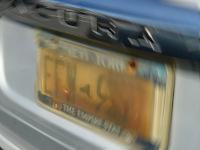

Ok ! That looks like the right image/post!

Now use it to find information about its owner.


In [41]:
encoded_image = social_df.loc[397, "image"]

MysteryUtils.check("image", encoded_image)

In [42]:
dmv_df.head()
dmv_df[dmv_df["plate_number"] == "EFW9376"]

,license_id,age,height,eye_color,hair_color,gender,plate_number,car_make,car_model
0,100280,72,57,brown,red,male,EFW9376,Acura,MDX


In [43]:
person_df[person_df["license_id"] == 100280]

,name,license_id,address_number,address_street,ssn
1390,Alfonzo Lighter,100280,2380,Demeo Rd,158688705


### Check Answer

Check the found clues below.

In [44]:
# TODO: put witness's email address here
wit_email_address = "someone@somewhere.com"
MysteryUtils.check("email", wit_email_address)

Hmm ! That email address doesn't seem right.
Run Homework08_utils.check("email", email_address, hint=True) for a hint.


### Find Visual Evidence

Once we have the email address for the witness, we can search for relevant posts with images that were created around the time of the crime.

The images are stored on the `DataFrame` as [$\text{Base}64$-encoded](https://en.wikipedia.org/wiki/Base64) text. This is a common technique for transmitting or storing different types of information when the available channels only support text.

Don't worry about decoding the image. Once you've found something using the other columns of the dataset, you can check the answer and get the decoded image using the `MysteryUtils.check()` function.

We can use [`str.contains()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.contains.html) and [`str.startswith()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.startswith.html) to filter the `date` column of a `DataFrame`.

In [45]:
# TODO: find relevant posts with images using the email, status and datetime columns

In [46]:
# TODO: find relevant posts with images using the email, status and datetime columns
all_posts = social_df[social_df["email"] == wit_email]
all_posts

image_posts = all_posts[all_posts["image"] != ""]
image_posts

relevant_image_posts = image_posts[(image_posts["datetime"].str.startswith("2026")) & 
                                    image_posts["status"].str.contains("package")]
relevant_image_posts

,datetime,email,status,image
397,20260127_142033,rrazze84@gmail.com,OMG! Saw these porch pirates taking packages i...,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBw...


### Check Answer

Check and visualize the image below.

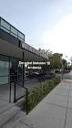

Hmm ! That doesn't seem right.
Run Homework08_utils.check("image", encoded_image, hint=True) for a hint.


In [47]:
# TODO: put the encoded image text in the following variable
encoded_image = social_df.iloc[5]["image"]
MysteryUtils.check("image", encoded_image)

### Follow the Evidence

Now we can use the image we just found and the `dmv` dataset to narrow down the list of potential suspects from the gym.

In order to make the connection between `dmv` and `gym` datasets we need people's names. The `license_id` field can be _transformed_/_translated_ into a name using the `person` dataset one more time. The `apply()` function can help here with this step.

We can create a list of values by _applying_ a function to each row of a `DataFrame`.

For example, this combines the first and last name columns of a `DataFrame` into a list of names, and adds the result as a column to the original `DataFrame`:

```py
def combine_names(row):
  return row["first_name"] + " " + row["last_name"]

full_names = list(people_df.apply(combine_names, axis=1))

people_df["full_name"] = full_names
```

The overall process is:
- find people in the `dmv` dataset related to the image found in the previous step
- get their `name` from their `license_id`
- see if any of them are also in the list of suspects from the gym.

We have a couple of options to do the last step. We can use a `for` loop and iterate over the `gym` names while checking if any of them are in the list of names from the `dmv`. Or, we can do the opposite and iterate over the `dmv` names while checking if any of them are in the `gym` list.

OR, we can use `set` objects to find the _intersection_ between the $2$ lists. These `set` objects are like lists, but they only keep unique items.

```py
mylist = [0,2,2,4,4,4,6,7,8]
myset = set(mylist)
print(myset)
>>> {0, 2, 4, 6, 7, 8}
```

SO, they are great for doing _Venn diagram_ type of operations:

<div style="overflow:hidden;">
  <img style="margin-top:-40px;" src="https://media.geeksforgeeks.org/wp-content/uploads/20240711100807/Set-operations.png" width=600>
</div>

`set` [documentation](https://docs.python.org/3.10/library/stdtypes.html#set) and [examples](https://www.w3schools.com/python/python_sets.asp).

In [48]:
# TODO: get names from dmv dataset
# TODO: cross-reference with names of potential suspects from gym

### Check Answer

Check the name of the suspect here.

In [49]:
# TODO: put the name of the suspect here
suspect_name = "HERE"
MysteryUtils.check("suspect", suspect_name)

Hmm ! That name doesn't seem right.
Run Homework08_utils.check("suspect", suspect_name, hint=True) for a hint.
